In [ ]:
# Instalar os pacotes no ambiente do notebook (só na primeira vez)
%pip install rioxarray geopandas contextily cartopy pyarrow

In [12]:
# ==== Pacotes ====
import os, tempfile, urllib.request
import numpy as np
import rioxarray                          # leitura e processamento de rasters (acessor .rio do xarray)
import geopandas as gpd                   # leitura e processamento de vetores
import contextily as ctx                  # baixa imagens de satélite para usar como fundo do mapa
import cartopy.crs as ccrs                # mapa projetado com coordenadas em graus nos eixos
import matplotlib.pyplot as plt           # gráficos
import matplotlib.ticker as mticker
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from pyproj import Geod, Transformer      # cálculo de área geodésica
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds

In [13]:
# ==== 1. ABRIR ====
# Dado: Área Queimada AQ1km do INPE (mensal, pixels de ~1 km, América do Sul)
# Mês da análise no formato AAAAMM (set/2024, temporada de fogo no Pantanal)
ano_mes = "202409"

# Montar o link do arquivo do mês e baixá-lo para a pasta temporária
url = f"https://dataserver-coids.inpe.br/queimadas/queimadas/area_queimada/AQ1km/tif/aqm1km_{ano_mes}.tif"
tmp = os.path.join(tempfile.gettempdir(), f"aqm1km_{ano_mes}.tif")
urllib.request.urlretrieve(url, tmp)

# Ler o raster (1 banda) e ver os metadados: tamanho, resolução, extensão e sistema de coordenadas
r = rioxarray.open_rasterio(tmp).squeeze("band", drop=True)
print(r.shape, r.rio.resolution(), r.rio.bounds(), r.rio.crs)

(6300, 5000) (0.01, -0.01) (-83.005, -49.995000000000005, -33.004999999999995, 13.005) EPSG:4326


In [14]:
# ==== 2. REPROJETAR ====
# O raster original está em graus (WGS 84), unidade ruim para medir distâncias e áreas
# Converter para metros: SIRGAS 2000 / Policônica do Brasil (EPSG:5880)
# Resampling.nearest: copia o valor do pixel mais próximo, sem criar valores intermediários
#   (essencial para dados de categoria, como queimado / não queimado)
# resolution=1000: pixels de 1.000 m x 1.000 m, equivalente à resolução original
r_m = r.rio.reproject("EPSG:5880", resolution=1000, resampling=Resampling.nearest)

In [15]:
# ==== 3. RECORTAR ====
# Baixar os biomas do IBGE (2019) e selecionar o Pantanal
# Arquivo oficial do projeto geobr (Ipea), o mesmo usado pelo read_biomes() no R
url_bio = "https://github.com/ipea/geobr_prep_data/releases/download/v2.0.0/biomes_2019_simplified.parquet"
tmp_bio = os.path.join(tempfile.gettempdir(), "biomas_2019.parquet")
urllib.request.urlretrieve(url_bio, tmp_bio)
biomas = gpd.read_parquet(tmp_bio)

# Colocar o limite na mesma projeção do raster
# (raster e vetor precisam estar no mesmo sistema de coordenadas para se sobrepor)
pantanal = biomas[biomas["name_biome"] == "Pantanal"].to_crs(r_m.rio.crs)

# clip(): corta o raster no retângulo que envolve o Pantanal (drop=True)
#   e apaga os pixels fora do limite do bioma
# all_touched=True: mantém os pixels tocados pelo limite (mesmo critério do terra::mask no R)
r_pant = r_m.rio.clip(pantanal.geometry, all_touched=True, drop=True)

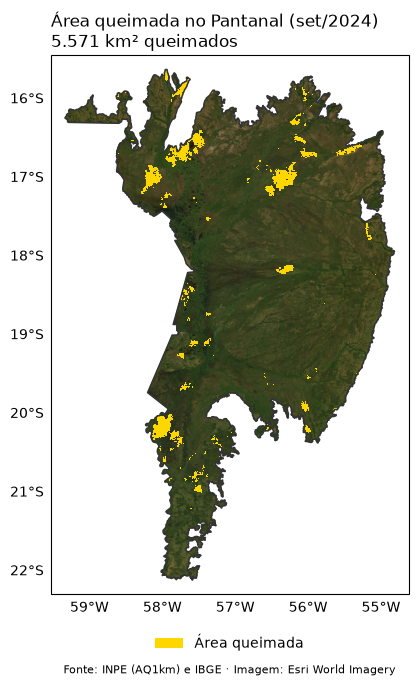

In [16]:
# ==== 4. RESULTADO ====
# No AQ1km, pixel = 1 indica área queimada no mês
# Manter só esses pixels; os demais viram NaN (não aparecem no mapa)
queimado = r_pant.where(r_pant == 1)

# Área queimada em km²: soma da área real (geodésica) de cada pixel queimado
#   (mesmo cálculo do terra::expanse no R: cantos do pixel convertidos para lon/lat)
lin, col = np.nonzero(queimado.notnull().values)
meio_x, meio_y = [abs(v) / 2 for v in queimado.rio.resolution()]
xc, yc = queimado.x.values[col], queimado.y.values[lin]
cantos_x = np.stack([xc - meio_x, xc + meio_x, xc + meio_x, xc - meio_x], axis=1)
cantos_y = np.stack([yc - meio_y, yc - meio_y, yc + meio_y, yc + meio_y], axis=1)
lon, lat = Transformer.from_crs("EPSG:5880", "EPSG:4326", always_xy=True).transform(cantos_x, cantos_y)
geod = Geod(ellps="WGS84")
area_km2 = sum(abs(geod.polygon_area_perimeter(lo, la)[0]) for lo, la in zip(lon, lat)) / 1e6

# Imagem de satélite de fundo (Esri World Imagery, cores reais)
# zoom=9: nível de detalhe adequado para uma região do tamanho do Pantanal
# Os tiles vêm em Web Mercator (EPSG:3857): baixar na extensão do Pantanal e reprojetar para EPSG:5880
w, s, e, n = pantanal.to_crs("EPSG:3857").total_bounds
sat, ext = ctx.bounds2img(w, s, e, n, zoom=9, source=ctx.providers.Esri.WorldImagery)
sat, ext = ctx.warp_tiles(sat, ext, t_crs="EPSG:5880")   # ext = (xmin, xmax, ymin, ymax)

# Manter a imagem só dentro do Pantanal: pixels fora do limite ficam transparentes
fora = geometry_mask(pantanal.geometry, out_shape=sat.shape[:2], all_touched=True,
                     transform=from_bounds(ext[0], ext[2], ext[1], ext[3], sat.shape[1], sat.shape[0]))
sat = np.dstack([sat[:, :, :3], np.where(fora, 0, 255).astype(np.uint8)])

# Mapa: as camadas são desenhadas na ordem em que aparecem (fundo primeiro)
proj = ccrs.epsg(5880)                                    # mapa em metros (Policônica)
xmin, ymin, xmax, ymax = queimado.rio.bounds()

fig = plt.figure(figsize=(6, 7))
ax = fig.add_subplot(projection=proj)
ax.imshow(sat, extent=ext, origin="upper", transform=proj)               # satélite
ax.imshow(queimado.values, extent=(xmin, xmax, ymin, ymax), origin="upper", transform=proj,
          interpolation="nearest", cmap=ListedColormap(["#FFD700"]))      # pixels queimados
# Amarelo vivo: lembra fogo, contrasta com a vegetação e é legível por daltônicos
ax.add_geometries(pantanal.geometry, crs=proj, facecolor="none",
                  edgecolor="0.2", linewidth=1.1)                         # contorno do bioma
x0, y0, x1, y1 = pantanal.total_bounds
ax.set_extent([x0 - 20000, x1 + 20000, y0 - 20000, y1 + 20000], crs=proj)   # margem de 20 km ao redor do bioma

# Moldura com coordenadas em graus, sem linhas de grade internas
gl = ax.gridlines(draw_labels=True, linewidth=0)
gl.top_labels = gl.right_labels = False
gl.xlocator = mticker.FixedLocator(range(-60, -53))
gl.ylocator = mticker.FixedLocator(range(-23, -14))

# Títulos, legenda e fonte
area_txt = f"{round(area_km2):,}".replace(",", ".")
ax.set_title(f"Área queimada no Pantanal (set/2024)\n{area_txt} km² queimados", loc="left", fontsize=12)
ax.legend(handles=[Patch(facecolor="#FFD700", label="Área queimada")],
          loc="upper center", bbox_to_anchor=(0.5, -0.05), frameon=False)
ax.text(0.5, -0.13, "Fonte: INPE (AQ1km) e IBGE · Imagem: Esri World Imagery",
        transform=ax.transAxes, ha="center", va="top", fontsize=8)

plt.show()

In [ ]:
# Salvar o mapa em PNG, com 300 dpi (alta resolução) e fundo branco
fig.savefig("area_queimada_pantanal_202409.png", dpi=300, facecolor="white", bbox_inches="tight")